In [1]:
# ok in this notebook we want to achieve minimum loss

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

words = open('names.txt', 'r').read().splitlines()

chars = sorted(list(set(''.join(words))))
char_to_int = {char: idx + 1 for idx, char in enumerate(chars)}
char_to_int['.'] = 0
int_to_char = {idx:char for char,idx in char_to_int.items()}

block_size = 3

def build_dataset(words):
    x_context, y_outputs = [], []

    for w in words:

        context = [0]* block_size
        for ch in w + '.':
            ix = char_to_int[ch]
            x_context.append(context)
            y_outputs.append(ix)
            context = context[1:] + [ix]

    x_context = torch.tensor(x_context)
    y_outputs = torch.tensor(y_outputs)
    print(x_context.shape, y_outputs.shape)
    return x_context,y_outputs

import random
random.seed(42)
random.shuffle(words)
part80 = int(0.8*len(words))
part90 = int(0.9*len(words))

x_train, y_train = build_dataset(words[:part80])
x_dev, y_dev = build_dataset(words[:part90])
x_test, y_test = build_dataset(words[part90:])

g = torch.Generator().manual_seed(2147483647)
embeddings_table = torch.randn((27,10), generator=g) #changed from 2 to 10
weights1 = torch.randn((30,200), generator=g)
bias1 = torch.randn(200, generator=g)
weights2 = torch.randn((200,27), generator=g)
bias2 = torch.randn(27, generator=g)
parameters = [embeddings_table, weights1, bias1, weights2, bias2]

for p in parameters:
    p.requires_grad = True

print(sum(p.nelement() for  p in parameters))

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([205280, 3]) torch.Size([205280])
torch.Size([22866, 3]) torch.Size([22866])
11897


In [3]:
# the idea now is split the training data set, fine tune, and test
#for that purpose we need to have a function to build data sets and to give the 80-10-10 percents<<

In [42]:
stepi = []
lossi = []

for __ in range(1):
    for i in range(30000):

        # minibatch
        ix = torch.randint(low=0, high=x_train.shape[0],size=(32,)) # random 32 numbers

        #forward pass
        emb = embeddings_table[x_train[ix]]
        h = torch.tanh(emb.view(-1,30)@weights1+bias1)
        logits = h @ weights2 + bias2
        loss = F.cross_entropy(input=logits, target=y_train[ix])

        for p in parameters:
            p.grad = None

        loss.backward()

        lr = 0.001
        for p in parameters:
            p.data += -lr*p.grad

        stepi.append(i)
        lossi.append(loss.item())

In [43]:
# test with dev set
# when this number is starting to get lower while the test loss is getting higher that means we are starting to overfit
emb = embeddings_table[x_train]
h = torch.tanh(emb.view(-1,30)@weights1+bias1)
logits = h @ weights2 + bias2
loss = F.cross_entropy(input=logits, target=y_train)
loss

tensor(2.1148, grad_fn=<NllLossBackward0>)

In [44]:
# test with dev set
emb = embeddings_table[x_dev]
h = torch.tanh(emb.view(-1,30) @ weights1 + bias1)
logits = h @ weights2 + bias2
loss = F.cross_entropy(input=logits, target=y_dev)
loss

tensor(2.1190, grad_fn=<NllLossBackward0>)

In [45]:
# test with test set just once when you think the model is perfect and the result of the test set is what would you put in the paper
emb = embeddings_table[x_test]
h = torch.tanh(emb.view(-1,30) @ weights1 + bias1)
logits = h @ weights2 + bias2
loss = F.cross_entropy(input=logits, target=y_test)
loss #record tensor(2.2444, grad_fn=<NllLossBackward0>)

tensor(2.1530, grad_fn=<NllLossBackward0>)

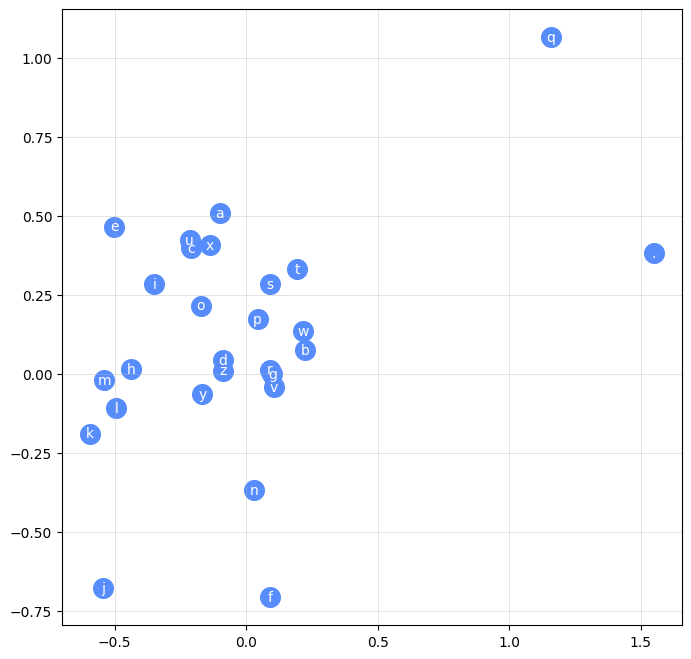

In [18]:
# here we are seeing the x,y are the embedding locations for each char in the table
plt.figure(figsize=(8,8))
plt.scatter(embeddings_table[:,0].data, embeddings_table[:,1].data, s=200)
for i in range(embeddings_table.shape[0]):
    plt.text(embeddings_table[i,0].item(), embeddings_table[i,1].item(), int_to_char[i], ha="center", va="center", color="white")
plt.grid("minor")
#as we can see a lot of the characters are embedded too similarly so that's maybe confusing our nn
# in the next notebook we will embedd using 30 floats not just 2

In [49]:
# sample from the model
g = torch.Generator().manual_seed(2147483647+10)

for _ in range(20):

    out = []
    context = [0]*block_size
    while True:
        emb = embeddings_table[torch.tensor([context])]
        h = torch.tanh(embeddings_table.view(1,-1) @ weights1 + bias1)
        logits = h @ weights2 + bias2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:]+[ix]
        out.append(ix)
        if ix == 0:
            break

    print(''.join(int_to_char[i] for i in out))

RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x270 and 30x200)